# Covered Bond Programme Scoring from the Harmonised Transparency Template: Agency-Style Scorecard and Ordinal ML Market-Implied Tiers

Almost every labelled covered bond programme is rated AAA, so the ratings barely tell programmes apart. Their spreads do. Issuers publish a standard template describing each cover pool, which makes the programmes comparable field by field. This notebook builds a transparent agency-style score from those templates and then asks which disclosed characteristics the market actually prices.

**What it does.** It downloads every published **Harmonised Transparency Template (HTT)** of the mortgage covered bond programmes that carry the Covered Bond Label: about 115 programmes, every half-year since mid-2023. Cover-pool and structural metrics are parsed directly from the standard field codes.

Two scores are built from the HTT metrics:

- an **agency-style scorecard**: transparent points for collateral quality, refinancing risk, market-risk mismatches and the overcollateralisation cushion, combined like a rating agency's collateral and structure assessment;
- a **market-implied score**: the programmes are matched to their outstanding euro benchmark covered bonds, their maturity-adjusted spreads over the ECB AAA curve are ranked into five tiers, and an **ordinal logit** and **LightGBM** learn the tiers from HTT metrics and sovereign risk.

The result shows which disclosed characteristics the market prices, and gives a shadow score for programmes with no euro benchmark bonds.

**Data.** The Covered Bond Label HTT database (coveredbondlabel.com), iShares € Covered Bond UCITS ETF month-end holdings (bond prices), and from the ECB the AAA euro-area yield curve (Svensson parameters) and ten-year government bond yields.

**Methods.** HTT parsing by field code, an expert scorecard, fuzzy entity matching, ordinal logistic regression, LightGBM with programme-grouped cross-validation, SHAP and K-means peer groups.

## 1. What the HTT is and how agencies use it

Since 2016, issuers carrying the Covered Bond Label have published a standardised quarterly template for each programme, the HTT. It is the main public source on cover-pool quality. Every field has a fixed code, which makes thousands of templates comparable:
- `G.3.2.1`: overcollateralisation, legal minimum and actual;
- `G.3.4.1` and `G.3.5.1`: weighted average life of the cover assets and of the bonds;
- `M.7A.11.1`: weighted average LTV;
- `M.7.9.1`: non-performing loans.

Rating agencies rate covered bonds as **issuer anchor + uplift**. The uplift depends on:
- the legal framework and the resolution regime;
- the **collateral quality**: LTV, arrears, concentration, seasoning, commercial exposure;
- the **refinancing risk**: the maturity mismatch between assets and bonds, and soft/hard bullet structures;
- **market risks**: interest-rate and currency mismatches;
- the **OC cushion** above the legal minimum, which absorbs all of the above.

Almost every labelled programme is rated AAA/Aaa, so the ratings themselves barely discriminate. Spreads do. That is why this notebook learns a market-implied score as well.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import difflib
import unicodedata
import openpyxl
import zipfile
import lightgbm as lgb
import shap
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from statsmodels.miscmodels.ordinal_model import OrderedModel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 29
CBL = "https://www.coveredbondlabel.com"
FUND_URL = (
    "https://www.ishares.com/ch/professionals/en/products/251842/ishares-covered-bond-ucits-etf/"
    "1495092304805.ajax?fileType=csv&fileName=ICOV_holdings&dataType=fund&asOfDate={}"
)
ECB = "https://data-api.ecb.europa.eu/service/data/{}?format=csvdata&startPeriod=2023-01-01"
EA = {
    "Austria": "AT",
    "Belgium": "BE",
    "Finland": "FI",
    "France": "FR",
    "Germany": "DE",
    "Ireland": "IE",
    "Italy": "IT",
    "Netherlands": "NL",
    "Portugal": "PT",
    "Spain": "ES",
    "Slovakia": "SK",
    "Slovak Republic": "SK",
    "Slovenia": "SI",
    "Estonia": "EE",
    "Lithuania": "LT",
    "Latvia": "LV",
    "Luxembourg": "LU",
    "Cyprus": "CY",
    "Greece": "GR",
}
N_TIERS = 5

print(
    f"lightgbm {lgb.__version__} · shap {shap.__version__} · openpyxl"
    f" {openpyxl.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · shap 0.54.1 · openpyxl 3.1.5 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Downloading and parsing the HTTs

The HTT database lists every parsed template with its programme and cut-off date. Its download endpoint returns the original Excel files for any selection, and files are kept for cut-off dates from mid-2023 onwards.

For each **mortgage** programme, the last template of every half-year (2023-H2 to 2026-H2) is downloaded, in batches. Each workbook is read cell by cell: a row is identified by the field code in its first column, which is stable across template versions. Ratios reported as 0–100 instead of 0–1 are rescaled. Templates that cannot be opened (old `.xls` binaries) are skipped.

In [3]:
H = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}


def fnum(v):
    if v is None:
        return np.nan
    if isinstance(v, (int, float)):
        return float(v)
    s = str(v).strip().replace(",", "").replace("%", "")
    try:
        return float(s)
    except ValueError:
        return np.nan


def rows_by_code(ws):
    out = {}
    for row in ws.iter_rows(values_only=True):
        cells = [c for c in row if c not in (None, "")]
        if cells and isinstance(cells[0], str):
            code = cells[0].strip()
            if re.match(r"^O?[A-Z]{1,2}\.\d", code) and code not in out:
                out[code] = cells[1:]
    return out


def first_num(cells, k=0):
    nums = [fnum(c) for c in cells[1:]] if cells else []
    nums = [x for x in nums if not np.isnan(x)]
    return nums[k] if len(nums) > k else np.nan


def parse_htt(content):
    wb = openpyxl.load_workbook(
        io.BytesIO(content), read_only=True, data_only=True
    )
    sh = {s.split(".")[0].strip(): s for s in wb.sheetnames}
    gen = next((s for s in wb.sheetnames if "General" in s), None)
    mort = next(
        (s for s in wb.sheetnames if "Mortgage" in s and "HTT" in s), None
    )
    if gen is None:
        return None
    G = rows_by_code(wb[gen])
    M = rows_by_code(wb[mort]) if mort else {}
    lab = lambda d, code: (
        str(d[code][1]) if d.get(code) and len(d[code]) > 1 else ""
    )
    r = {
        "country": lab(G, "G.1.1.1"),
        "issuer": lab(G, "G.1.1.2"),
        "pool": lab(G, "G.1.1.3"),
        "cutoff": lab(G, "G.1.1.5"),
    }
    r["cover_assets"] = first_num(G.get("G.3.1.1"))
    r["covered_bonds"] = first_num(G.get("G.3.1.2"))
    oc = G.get("G.3.2.1") or []
    ocn = [fnum(c) for c in oc[1:]]
    r["oc_legal_min"], r["oc_actual_rep"], r["oc_committed"] = (
        ocn + [np.nan] * 3
    )[:3]
    r["share_mortgage"] = first_num(G.get("G.3.3.1"), 1)
    r["share_public"] = first_num(G.get("G.3.3.2"), 1)
    r["share_substitute"] = first_num(G.get("G.3.3.4"), 1)
    r["wal_assets"] = first_num(G.get("G.3.4.1"))
    r["wal_bonds"] = first_num(G.get("G.3.5.1"))
    eur_a, eur_b = first_num(G.get("G.3.6.1")), first_num(G.get("G.3.7.1"))
    r["eur_share_assets"] = (
        eur_a / r["cover_assets"] if r["cover_assets"] else np.nan
    )
    r["eur_share_bonds"] = (
        eur_b / r["covered_bonds"] if r["covered_bonds"] else np.nan
    )
    fb = G.get("G.3.8.1") or []
    fbn = [fnum(c) for c in fb[1:]]
    fbn = [x for x in fbn if not np.isnan(x)]
    r["fixed_share_bonds"] = (
        fbn[2]
        if len(fbn) >= 3 and fbn[2] <= 1.0001
        else (
            fbn[0] / r["covered_bonds"]
            if fbn and r["covered_bonds"]
            else np.nan
        )
    )
    # mortgage block
    tot = first_num(M.get("M.7.1.4"))
    r["share_residential"] = (
        first_num(M.get("M.7.1.1")) / tot if tot else np.nan
    )
    r["share_commercial"] = (
        first_num(M.get("M.7.1.2")) / tot if tot else np.nan
    )
    r["n_loans"] = first_num(M.get("M.7.2.1"))
    r["top10_share"] = first_num(M.get("M.7.3.1"))
    r["domestic_share"] = np.nan
    r["fixed_share_assets"] = first_num(M.get("M.7.6.1"))
    r["bullet_share"] = first_num(M.get("M.7.7.1"))
    r["seasoning_gt60m"] = first_num(M.get("M.7.8.5"))
    r["npl_share"] = first_num(M.get("M.7.9.1"))

    # residential detail: average loan size, LTV unindexed / indexed, occupancy
    # (code families differ by template year)
    def find(prefix_label, nth=0):
        hits = [
            v
            for k, v in M.items()
            if re.match(r"^M\.7A?\.\d+\.1$", k)
            and v
            and str(v[0]).lower().startswith(prefix_label)
        ]
        return first_num(hits[nth]) if len(hits) > nth else np.nan

    r["avg_loan_k"] = find("average loan size", 0)
    r["ltv_unindexed"] = find("weighted average ltv", 0)
    r["ltv_indexed"] = find("weighted average ltv", 1)
    r["owner_occupied"] = find("owner occupied", 0)
    # LTV > 80% share (unindexed table): sum of buckets after the header row
    # whose label starts with ">80" or ">90" or ">100"
    ltv_codes = [
        k
        for k, v in M.items()
        if v and str(v[0]).lower().startswith("weighted average ltv")
    ]
    if ltv_codes:
        fam = ltv_codes[0].rsplit(".", 1)[0]
        hi = 0.0
        any_ = False
        for k, v in M.items():
            if (
                k.startswith(fam + ".")
                and v
                and re.match(r"^\s*>\s*(80|90|100)", str(v[0]))
            ):
                nums = [fnum(c) for c in v[1:]]
                nums = [x for x in nums if not np.isnan(x)]
                share = [x for x in nums if x <= 1.0001]
                if share:
                    hi += share[-1]
                    any_ = True
        r["ltv_gt80_share"] = hi if any_ else np.nan
    else:
        r["ltv_gt80_share"] = np.nan
    for k in (
        "ltv_unindexed",
        "ltv_indexed",
        "npl_share",
        "top10_share",
        "seasoning_gt60m",
        "owner_occupied",
        "fixed_share_assets",
        "bullet_share",
    ):
        if r[k] > 1.5:
            # some issuers report percentages as 0–100
            r[k] = r[k] / 100
    return r


def download_batch(ids):
    url = (
        "https://www.coveredbondlabel.com/htt-database/compare/download?parsings="
        + "-".join(map(str, ids))
    )
    z = zipfile.ZipFile(
        io.BytesIO(requests.get(url, headers=H, timeout=300).content)
    )
    return {n: z.read(n) for n in z.namelist()}


def list_parsings():
    hdr = {**BROWSER_HEADERS, "X-Requested-With": "XMLHttpRequest"}
    rows, page = [], 1
    while True:
        j = requests.get(
            f"{CBL}/htt-database/ajax-parsings",
            params={"page": page, "rowCount": 500},
            headers=hdr,
            timeout=60,
        ).json()
        rows += j["rows"]
        if len(rows) >= j["total"] or not j["rows"]:
            break
        page += 1
    strip = lambda s: re.sub(r"<[^>]+>", "", s or "").strip()
    out = pd.DataFrame([
        {
            "id": r["id"],
            "pool_id": (
                re.search(r"/pool/(\d+)", r["identifier"] or "")
                or [None, None]
            )[1],
            "pool": strip(r["identifier"]),
            "issuer": strip(r["issuer"]),
            "country": strip(r["country"]),
            "cutoff": r["cutoffdate"],
            "type": r["type"],
        }
        for r in rows
    ])
    out["cutoff"] = pd.to_datetime(
        out["cutoff"], format="%d/%m/%Y", errors="coerce"
    )
    return out


def fetch_htt_panel():
    p = list_parsings()
    p = p[(p["type"] == "Mortgage") & (p["cutoff"] >= "2023-07-01")].copy()
    p["half"] = (
        p["cutoff"].dt.year.astype(str)
        + "H"
        + ((p["cutoff"].dt.month > 6) + 1).astype(str)
    )
    sel = p.sort_values("cutoff").groupby(["pool_id", "half"]).tail(1)
    res = []
    for half, g in sel.groupby("half"):
        ids = g["id"].tolist()
        for k in range(0, len(ids), 12):
            try:
                files = download_batch(ids[k : k + 12])
            except Exception:
                files = {}
            for n, c in files.items():
                try:
                    r = parse_htt(c)
                except Exception:
                    r = None
                if r:
                    r.update(file=n, half=half)
                    res.append(r)
            time.sleep(0.5)
    return pd.DataFrame(res)


htt = cached("htt_features", fetch_htt_panel, max_age_hours=24 * 30)
_c = htt["cutoff"].astype(str).str[:10]
htt["cutoff"] = (
    pd.to_datetime(_c, format="%Y-%m-%d", errors="coerce")
    .fillna(pd.to_datetime(_c, format="%d-%m-%Y", errors="coerce"))
    .fillna(pd.to_datetime(_c, format="%d/%m/%Y", errors="coerce"))
)
# a few templates carry a mistyped year
htt["cutoff"] = htt["cutoff"].where(htt["cutoff"] > "2015-01-01")
half_end = pd.to_datetime(
    htt["half"].str[:4]
    + np.where(htt["half"].str.endswith("1"), "-06-30", "-12-31")
)
htt["cutoff"] = htt["cutoff"].fillna(
    half_end.clip(upper=pd.Timestamp(dt.date.today()))
)
CTY = {
    "the netherlands": "Netherlands",
    "spain & portugal": "Spain",
    "korea": "Republic of Korea (South)",
    "slovakia": "Slovakia",
}
htt["country"] = (
    htt["country"]
    .str.strip()
    .map(lambda s: CTY.get(s.lower(), s.title() if s.isupper() else s))
)
htt = (
    htt[htt["country"].ne("")]
    .dropna(subset=["cover_assets", "covered_bonds"])
    .query("covered_bonds > 0")
    .copy()
)
for c_ in [
    "top10_share",
    "ltv_gt80_share",
    "share_commercial",
    "npl_share",
    "seasoning_gt60m",
    "owner_occupied",
]:
    # amounts reported in a share field are discarded
    htt[c_] = htt[c_].where(htt[c_].between(0, 1))
for c_ in ["ltv_unindexed", "ltv_indexed", "n_loans"]:
    htt[c_] = htt[c_].where(htt[c_] > 0)
htt["issuer"], htt["pool"] = htt["issuer"].str.strip(), htt["pool"].str.strip()
htt["programme"] = htt["issuer"] + " | " + htt["pool"]
htt = htt.sort_values("cutoff").drop_duplicates(
    ["programme", "half"], keep="last"
)
print(
    f"{len(htt)} templates · {htt['programme'].nunique()} programmes ·"
    f" {htt['country'].nunique()} countries · cut-offs"
    f" {htt['cutoff'].min():%Y-%m} → {htt['cutoff'].max():%Y-%m}"
)
htt.groupby("country")["programme"].nunique().sort_values(
    ascending=False
).head(15).to_frame("programmes")

557 templates · 173 programmes · 22 countries · cut-offs 2023-12 → 2026-10


,programmes
country,
Italy,24
Spain,17
Germany,16
Netherlands,14
Finland,14
United Kingdom,14
Denmark,10
Norway,9
Portugal,9


## 4. Metrics and the agency-style scorecard

**Derived metrics.**

| metric | definition | risk direction |
|---|---|---|
| actual OC | cover assets / covered bonds − 1 | cushion (higher = safer) |
| OC buffer | actual OC − legal minimum | cushion |
| WAL gap | contractual WAL of assets − WAL of bonds (years) | refinancing need (higher = riskier) |
| rate mismatch | \|fixed share of assets − fixed share of bonds\| | interest-rate risk |
| FX mismatch | \|EUR share of assets − EUR share of bonds\| | currency risk |
| LTV | weighted average indexed LTV (unindexed if not reported) | collateral |
| LTV > 80% | share of the pool above 80% LTV | tail collateral |
| NPL | non-performing loan share | collateral |
| commercial share | commercial mortgages in the mortgage pool | collateral |
| top-10 share, loans | concentration and granularity | collateral |
| seasoning | share of loans older than 5 years | collateral (seasoned = safer) |
| substitute assets | share of liquid substitute assets | liquidity (two-sided) |

**Scorecard.** Each metric gets 1 (strong) to 5 (weak) points on fixed thresholds, close to the bands agencies publish. The points are averaged within four pillars:
- collateral: 40%;
- refinancing: 25%;
- market risk: 15%;
- OC cushion: 20%.

The weighted result is rescaled to 0–100, where higher means stronger. It is deliberately simple and auditable, a typical first-line analyst tool.

In [4]:
h = htt.copy()
h["oc_actual"] = h["cover_assets"] / h["covered_bonds"] - 1
h["oc_buffer"] = h["oc_actual"] - h["oc_legal_min"].fillna(0.02)
h["wal_gap"] = h["wal_assets"] - h["wal_bonds"]
h["rate_mismatch"] = (h["fixed_share_assets"] - h["fixed_share_bonds"]).abs()
h["fx_mismatch"] = (h["eur_share_assets"] - h["eur_share_bonds"]).abs()
h["ltv"] = h["ltv_indexed"].fillna(h["ltv_unindexed"])
h["log_loans"] = np.log10(h["n_loans"].clip(lower=10))
for c_ in ["share_commercial", "npl_share", "top10_share", "ltv_gt80_share"]:
    h[c_] = h[c_].clip(0, 1)
BANDS = {  # metric: (thresholds for points 1|2|3|4|5, higher_is_worse)
    "ltv": ([0.50, 0.60, 0.70, 0.80], True),
    "ltv_gt80_share": ([0.02, 0.05, 0.10, 0.20], True),
    "npl_share": ([0.001, 0.005, 0.01, 0.03], True),
    "share_commercial": ([0.01, 0.05, 0.15, 0.30], True),
    "top10_share": ([0.005, 0.01, 0.03, 0.08], True),
    "log_loans": ([4.5, 4.0, 3.5, 3.0], False),
    "seasoning_gt60m": ([0.60, 0.45, 0.30, 0.15], False),
    "wal_gap": ([4, 7, 10, 15], True),
    "rate_mismatch": ([0.1, 0.25, 0.4, 0.6], True),
    "fx_mismatch": ([0.01, 0.05, 0.10, 0.20], True),
    "oc_buffer": ([0.30, 0.20, 0.10, 0.05], False),
}
PILLARS = {
    "collateral": (
        [
            "ltv",
            "ltv_gt80_share",
            "npl_share",
            "share_commercial",
            "top10_share",
            "log_loans",
            "seasoning_gt60m",
        ],
        0.40,
    ),
    "refinancing": (["wal_gap"], 0.25),
    "market risk": (["rate_mismatch", "fx_mismatch"], 0.15),
    "OC cushion": (["oc_buffer"], 0.20),
}


def points(x, th, worse_high):
    if pd.isna(x):
        return np.nan
    if worse_high:
        return 1 + int(np.searchsorted(th, x, side="right"))
    return 1 + int(np.searchsorted([-t for t in th], -x, side="right"))


for m_, (th, w) in BANDS.items():
    h[f"pt_{m_}"] = [points(v, th, w) for v in h[m_]]
for p_, (ms, w) in PILLARS.items():
    h[f"pillar_{p_}"] = h[[f"pt_{m_}" for m_ in ms]].mean(axis=1)
pil = [f"pillar_{p_}" for p_ in PILLARS]
wts = np.array([w for _, (_, w) in PILLARS.items()])
avail = h[pil].notna().to_numpy()
h["scorecard"] = (
    100
    * (
        5
        - np.nansum(h[pil].to_numpy() * wts, axis=1)
        / (avail * wts).sum(axis=1)
    )
    / 4
)
coverage_ = h[list(BANDS)].notna().mean().sort_values()
print(
    f"Scorecard computed for {h['scorecard'].notna().sum()} templates · median"
    f" {h['scorecard'].median():.0f}/100 · metric coverage from"
    f" {coverage_.min():.0%} ({coverage_.idxmin()}) to {coverage_.max():.0%}"
)
latest = h.sort_values("cutoff").groupby("programme").tail(1)
latest.groupby("country")[
    ["scorecard", "oc_actual", "ltv", "wal_gap", "npl_share"]
].median().sort_values("scorecard").round(3)

Scorecard computed for 557 templates · median 71/100 · metric coverage from 78% (ltv_gt80_share) to 100%


,scorecard,oc_actual,ltv,wal_gap,npl_share
country,,,,,
Iceland,49.51,0.26,0.52,27.02,0.00
Sweden,51.88,0.31,0.55,22.61,0.00
Estonia,54.91,0.34,0.56,10.38,0.00
United Kingdom,55.94,0.62,0.50,18.14,0.00
Norway,56.25,0.26,0.54,11.34,0.00
Republic of Korea (South),56.83,0.76,0.39,29.31,0.00
Singapore,57.50,1.29,0.46,20.03,0.00
Denmark,58.85,0.07,0.54,8.26,0.00
Portugal,62.23,0.21,0.53,16.13,0.00


## 5. Market prices: maturity-adjusted spreads of the programmes' euro benchmark bonds

For each half-year (June and December month-ends), the holdings of the iShares € Covered Bond ETF give the price of every euro benchmark covered bond. The z-spread is computed over the ECB AAA zero curve (Svensson parameters), with annual coupons and accrued interest.

To compare issuers with different maturity profiles, each bond's spread is expressed **relative to the median spread of bonds in the same maturity bucket that month**, and the issuer's median relative spread is kept. A programme's **market tier** is the quintile of that measure across matched programmes in the half-year: 1 is the tightest, 5 the widest.

**Matching.** ETF issuer names ("BNP PARIBAS HOME LOAN SFH SA") are matched to HTT issuer names ("BNP Paribas Home Loan SFH") within the same country. Legal forms and generic words (bank, covered bond, building society, caja…) are removed first. A pair matches when the remaining names are at least 82% similar or share their first distinctive word.

That second rule catches a covered bond company whose bonds trade under the parent bank's name, e.g. ABN AMRO. Every match is listed in the outputs for audit.

In [5]:
def fetch_icov(dates):
    out = []
    for m in dates:
        for back in range(6):
            d = (m - pd.tseries.offsets.BDay(back)).strftime("%Y%m%d")
            t = requests.get(
                FUND_URL.format(d), headers=BROWSER_HEADERS, timeout=60
            ).text
            lines = t.splitlines()
            head = next(
                (
                    i
                    for i, l in enumerate(lines[:10])
                    if l.startswith("Ticker")
                ),
                None,
            )
            if head is not None and len(lines) > 50:
                df = pd.read_csv(
                    io.StringIO("\n".join(lines[head:])),
                    dtype=str,
                    on_bad_lines="skip",
                )
                df["asof"] = pd.to_datetime(
                    lines[0].split('"')[1].replace("Sept", "Sep"),
                    format="%d/%b/%Y",
                )
                out.append(df)
                break
    return pd.concat(out, ignore_index=True)


halves = sorted(h["half"].unique())
month_end = {
    hf: pd.Timestamp(
        f"{hf[:4]}-{'06' if hf.endswith('1') else '12'}-30"
    ) + pd.offsets.BMonthEnd(0)
    for hf in halves
}
month_end = {
    k: min(v, pd.Timestamp(dt.date.today()) - pd.offsets.BMonthEnd(1))
    for k, v in month_end.items()
}
icov = cached(
    "icov_half_years",
    lambda: fetch_icov(sorted(set(month_end.values()))),
    max_age_hours=24 * 30,
)
yc = cached(
    "ecb_aaa_svensson",
    lambda: pd.read_csv(
        io.StringIO(
            requests.get(
                ECB.format(
                    "YC/B.U2.EUR.4F.G_N_A.SV_C_YM.BETA0+BETA1+BETA2+BETA3+TAU1+TAU2"
                ),
                timeout=120,
            ).text
        )
    ),
    max_age_hours=24 * 7,
)
lty = cached(
    "ecb_10y_yields",
    lambda: pd.read_csv(
        io.StringIO(
            requests.get(
                ECB.format(
                    "IRS/M."
                    + "+".join(sorted(set(EA.values())))
                    + ".L.L40.CI.0000.EUR.N.Z"
                ),
                timeout=120,
            ).text
        )
    ),
    max_age_hours=24 * 7,
)

num = lambda s: pd.to_numeric(
    s.astype(str).str.replace("’", "").str.replace(",", ""), errors="coerce"
)
b = icov[icov["Asset Class"] == "Fixed Income"].copy()
b["price"], b["coupon"] = num(b["Price"]), num(b["Coupon (%)"])
b["maturity"] = pd.to_datetime(
    b["Maturity"].str.replace("Sept", "Sep"),
    format="%d/%b/%Y",
    errors="coerce",
)
b["issuer_icov"] = (
    b["Name"]
    .str.upper()
    .str.replace(r"\s+(MTN|RegS|REGS|144A|EMTN)\b.*$", "", regex=True)
    .str.strip()
)
b = b.dropna(subset=["price", "coupon", "maturity"])
b["T"] = (b["maturity"] - b["asof"]).dt.days / 365.25
b = b[(b["T"] > 0.5) & b["price"].between(50, 160)].reset_index(drop=True)
P = yc.assign(par=yc["KEY"].str.split(".").str[-1]).pivot_table(
    index="TIME_PERIOD", columns="par", values="OBS_VALUE"
)
P.index = pd.to_datetime(P.index)


def svensson(t, b0, b1, b2, b3, t1, t2):
    t = np.maximum(t, 1e-6)
    x1, x2 = t / t1, t / t2
    f1 = (1 - np.exp(-x1)) / x1
    return (
        b0
        + b1 * f1
        + b2 * (f1 - np.exp(-x1))
        + b3 * ((1 - np.exp(-x2)) / x2 - np.exp(-x2))
    ) / 100


prm = (
    P.reindex(P.index.union(b["asof"].unique())).ffill().loc[b["asof"].values]
)
pr = [
    prm[c].to_numpy()[:, None]
    for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]
]
T, cpn = b["T"].to_numpy(), b["coupon"].to_numpy()
tk = T[:, None] - np.arange(int(np.ceil(T.max())))[None, :]
valid = tk > 0
tkz = np.where(valid, tk, 0.0)
dirty = b["price"].to_numpy() + cpn * (1 - (T - np.floor(T)))
r_ = svensson(np.where(valid, tk, 1.0), *pr)
cf = np.where(valid, cpn[:, None], 0.0)
cf[:, 0] += 100
z = np.zeros(len(T))
for _ in range(30):
    disc = np.where(valid, np.exp(-(r_ + z[:, None]) * tkz), 0.0)
    z -= ((cf * disc).sum(1) - dirty) / (-(cf * disc * tkz).sum(1))
b["z_bp"] = z * 1e4
b = b[b["z_bp"].between(-100, 500)].copy()
b["T_bucket"] = pd.cut(b["T"], [0, 2, 4, 6, 8, 10, 15, 40])
b["rel_bp"] = b["z_bp"] - b.groupby(["asof", "T_bucket"], observed=True)[
    "z_bp"
].transform("median")
iss_sp = (
    b.groupby(["asof", "issuer_icov", "Location"])
    .agg(
        rel_bp=("rel_bp", "median"),
        z_bp=("z_bp", "median"),
        bonds=("z_bp", "size"),
    )
    .reset_index()
)

STOP = (
    r"\b(SA|AG|PLC|NV|N V|BV|B V|AB|AS|ASA|OYJ|LTD|LIMITED|SPA|S P"
    r" A|SFH|SCF|BANK|BANCO|BANCA|BANQUE|THE|DE|DI|DER|DU|CO|COVERED|BOND|BONDS|"
    r"MORTGAGE|MORTGAGES|HYPOTEK|BOLIGKREDITT|PUBL|COMPANY|CORP|CORPORATION|BUILDING|SOCIETY|HOME|LOAN|LOANS|GROUP|CAJA|CAIXA|CREDITO|CREDIT|"
    r"RURAL|CASSA|CAISSE|RISPARMIO|REALKREDIT|SOCIEDAD|COOPERATIVA|COOP|SCC|S"
    r" C C|GMBH|AKTIENGESELLSCHAFT|KREDIT|REALKREDITAKTIESELSKAB|HYPOTHEKENBANK|NATIONAL)\b"
)
norm = lambda s: re.sub(
    STOP,
    " ",
    re.sub(
        r"[^A-Z ]",
        " ",
        unicodedata.normalize("NFKD", str(s))
        .encode("ascii", "ignore")
        .decode()
        .upper(),
    ),
).split()
CTY_FIX = {
    "Republic of Korea (South)": "Korea (South)",
    "Slovakia": "Slovak Republic",
    "Czechia": "Czech Republic",
}
matches = []
for (iss, cty), _ in h.groupby(["issuer", "country"]):
    # mortgage programmes only
    cand = iss_sp[
        (iss_sp["Location"] == CTY_FIX.get(cty, cty))
        & ~iss_sp["issuer_icov"].str.contains("PUBLIC")
    ]["issuer_icov"].unique()
    if not len(cand):
        continue
    ta = norm(iss)
    if not ta:
        continue
    sc = []
    for c in cand:
        tc = norm(c)
        r_ = difflib.SequenceMatcher(None, " ".join(ta), " ".join(tc)).ratio()
        first = (
            bool(tc) and len(ta[0]) >= 3 and ta[0] == tc[0]
        )  # same distinctive first word (e.g. "ABN AMRO", "NORDEA")
        sc.append((max(r_, 0.85 if first else 0.0), r_, c))
    best = max(sc)
    if best[0] >= 0.82:
        matches.append({
            "issuer": iss,
            "country": cty,
            "issuer_icov": best[2],
            "similarity": round(best[1], 3),
            "rule": "first word" if best[0] > best[1] else "similarity",
        })
match = pd.DataFrame(matches)
h["asof"] = h["half"].map(month_end)
h = h.merge(
    match[["issuer", "issuer_icov", "similarity"]], on="issuer", how="left"
)
asof_icov = {
    m: b.loc[(b["asof"] - m).abs().idxmin(), "asof"]
    for m in h["asof"].unique()
}
h["asof_icov"] = h["asof"].map(asof_icov)
h = h.merge(
    iss_sp.rename(columns={"asof": "asof_icov"})[
        ["asof_icov", "issuer_icov", "rel_bp", "z_bp", "bonds"]
    ],
    on=["asof_icov", "issuer_icov"],
    how="left",
)
mk = h.dropna(subset=["rel_bp"]).copy()
mk["tier"] = (
    mk.groupby("half")["rel_bp"].transform(
        lambda s: pd.qcut(s.rank(method="first"), N_TIERS, labels=False)
    )
    + 1
)
print(
    f"{len(match)} HTT issuers matched to ETF issuers (median similarity"
    f" {match['similarity'].median():.2f}) · {len(mk)} programme-half-years"
    f" with a market spread ({mk['programme'].nunique()} programmes)"
)
match.sort_values("similarity").head(8)

87 HTT issuers matched to ETF issuers (median similarity 1.00) · 376 programme-half-years with a market spread (117 programmes)


,issuer,country,issuer_icov,similarity,rule
55,MBH Mortgage Bank Co. Plc.,Hungary,MBH JELZALOGBANK NYRT,0.25,first word
62,OTP Mortgage Bank Ltd.,Hungary,OTP JELZALOGBANK ZRT,0.26,first word
36,Danske Mortgage Bank,Finland,DANSKE KIINNITYSLUOTTOPANKKI OY,0.32,first word
37,Danske Mortgage Bank Plc,Finland,DANSKE KIINNITYSLUOTTOPANKKI OY,0.32,first word
48,Iccrea Banca Spa,Italy,ICCREA BANCA ISTITUTO CENTRALE DEL,0.35,first word
47,Iccrea Banca S.p.A.,Italy,ICCREA BANCA ISTITUTO CENTRALE DEL,0.35,first word
30,Crédit Agricole Financement de l'Habitat SFH,France,CREDIT AGRICOLE HOME LOAN SFH,0.42,first word
7,BAWAG P.S.K.,Austria,BAWAG PSK BANK FUER ARBEIT UND WIR,0.45,first word


## 6. Does the market price what the HTT discloses?

Three sets of models predict the market tier and the maturity-adjusted spread. All are cross-validated with **programmes grouped**: a programme's half-years are never split between train and test.

1. **Country only:** sovereign spread plus country, the benchmark that the market prices jurisdiction first.
2. **Ordinal logit on the scorecard pillars:** the four pillar scores, OC buffer and sovereign spread, with a proportional-odds link. This is the transparent "rating model".
3. **LightGBM on the raw HTT metrics** plus sovereign spread: a regression on the relative spread, mapped to tiers by the training-set quintiles.

Metrics:
- Spearman rank correlation with the realised spread;
- exact tier accuracy;
- **within-one-tier accuracy**, the agency-style "within one notch".

In [6]:
mty = lty.assign(
    cc=lty["KEY"].str.split(".").str[2],
    m=pd.to_datetime(lty["TIME_PERIOD"]).dt.to_period("M"),
).pivot_table(index="m", columns="cc", values="OBS_VALUE")
aaa10 = pd.Series(
    svensson(
        10.0,
        *[P[c] for c in ["BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]]
    )
    * 100,
    index=P.index,
)
aaa10_m = aaa10.groupby(aaa10.index.to_period("M")).last()


def sov(row):
    cc, m_ = EA.get(row["country"]), row["asof_icov"].to_period("M")
    if cc is None or cc not in mty.columns:
        return np.nan
    v = mty[cc].loc[:m_].dropna()
    return (v.iloc[-1] - aaa10_m.loc[:m_].iloc[-1]) * 100 if len(v) else np.nan


mk["sov_spread"] = mk.apply(sov, axis=1)
mk["non_euro_area"] = mk["sov_spread"].isna().astype(int)
mk["country_c"] = mk["country"].astype("category")
RAW = [
    "oc_actual",
    "oc_buffer",
    "wal_gap",
    "rate_mismatch",
    "fx_mismatch",
    "ltv",
    "ltv_gt80_share",
    "npl_share",
    "share_commercial",
    "top10_share",
    "log_loans",
    "seasoning_gt60m",
    "share_substitute",
    "owner_occupied",
    "sov_spread",
]
y_rel, tier, grp = (
    mk["rel_bp"].to_numpy(),
    mk["tier"].to_numpy().astype(int),
    mk["programme"].to_numpy(),
)
pred = {
    k: np.full(len(mk), np.nan)
    for k in [
        "country only",
        "ordinal logit (scorecard pillars)",
        "LightGBM (HTT metrics)",
    ]
}
tier_pred = {k: np.full(len(mk), np.nan) for k in pred}
ORD = pil + ["oc_buffer", "sov_spread"]
for tr, te in GroupKFold(5).split(mk, groups=grp):
    a, t_ = mk.iloc[tr], mk.iloc[te]
    cuts = np.quantile(a["rel_bp"], np.linspace(0, 1, N_TIERS + 1)[1:-1])
    to_tier = lambda v: 1 + np.searchsorted(cuts, v)
    # 1) country only: median relative spread of the country in training
    # (sovereign spread for unseen countries)
    cm = a.groupby("country")["rel_bp"].median()
    lin = np.polyfit(a["sov_spread"].fillna(0), a["rel_bp"], 1)
    p1 = t_["country"].map(cm).to_numpy()
    p1 = np.where(
        np.isnan(p1), np.polyval(lin, t_["sov_spread"].fillna(0)), p1
    )
    pred["country only"][te], tier_pred["country only"][te] = p1, to_tier(p1)
    # 2) ordinal logit on pillars
    Xa = a[ORD].fillna(a[ORD].median())
    Xt = t_[ORD].fillna(a[ORD].median())
    sc = StandardScaler().fit(Xa)
    om = OrderedModel(
        a["tier"].astype(int).to_numpy(), sc.transform(Xa), distr="logit"
    ).fit(method="bfgs", disp=False, maxiter=500)
    probs = om.predict(sc.transform(Xt))
    tier_pred["ordinal logit (scorecard pillars)"][te] = probs.argmax(1) + 1
    pred["ordinal logit (scorecard pillars)"][te] = probs @ np.arange(
        1, N_TIERS + 1
    )
    # 3) LightGBM on raw metrics
    gb = lgb.LGBMRegressor(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=7,
        min_child_samples=15,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        verbose=-1,
        random_state=SEED,
    ).fit(a[RAW], a["rel_bp"])
    p3 = gb.predict(t_[RAW])
    (
        pred["LightGBM (HTT metrics)"][te],
        tier_pred["LightGBM (HTT metrics)"][te],
    ) = p3, to_tier(p3)
evals = pd.DataFrame({
    k: {
        "Spearman vs spread": stats.spearmanr(pred[k], y_rel)[0],
        "exact tier %": np.mean(tier_pred[k] == tier) * 100,
        "within one tier %": np.mean(np.abs(tier_pred[k] - tier) <= 1) * 100,
    }
    for k in pred
}).T
evals.loc["scorecard alone (higher score = tighter)"] = [
    stats.spearmanr(-mk["scorecard"], y_rel, nan_policy="omit")[0],
    np.nan,
    np.nan,
]
evals.loc["chance (5 tiers)"] = [0, 20, 52]
gb_full = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=7,
    min_child_samples=15,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    verbose=-1,
    random_state=SEED,
).fit(mk[RAW], y_rel)
sv = shap.TreeExplainer(gb_full).shap_values(mk[RAW])
shap_imp = pd.Series(np.abs(sv).mean(0), index=RAW).sort_values(
    ascending=False
)
Xf = mk[ORD].fillna(mk[ORD].median())
om_full = OrderedModel(
    tier, StandardScaler().fit_transform(Xf), distr="logit"
).fit(method="bfgs", disp=False, maxiter=500)
ord_coef = pd.Series(om_full.params[: len(ORD)], index=ORD).rename(
    "coefficient (per s.d.; + = wider tier)"
)
display(evals.round(2))
display(shap_imp.round(2).to_frame("mean |SHAP| on relative spread (bp)"))
ord_coef.round(3).to_frame()

,Spearman vs spread,exact tier %,within one tier %
country only,0.54,32.98,77.13
ordinal logit (scorecard pillars),0.45,25.53,63.56
LightGBM (HTT metrics),0.66,34.04,81.38
scorecard alone (higher score = tighter),-0.09,NaN,NaN
chance (5 tiers),0.00,20.00,52.00


,mean |SHAP| on relative spread (bp)
sov_spread,3.46
log_loans,2.74
ltv_gt80_share,1.32
owner_occupied,0.91
oc_actual,0.86
top10_share,0.68
wal_gap,0.62
share_substitute,0.61
fx_mismatch,0.56
seasoning_gt60m,0.55


,coefficient (per s.d.; + = wider tier)
pillar_collateral,0.20
pillar_refinancing,0.35
pillar_market risk,-0.14
pillar_OC cushion,-0.39
oc_buffer,0.04
sov_spread,0.93


## 7. Shadow scores for programmes without euro benchmarks, and peer groups

The LightGBM model, fitted on all matched programmes, scores **every** programme's latest template. That includes Danish, Norwegian, Polish, Korean or Canadian programmes whose euro benchmark bonds are not in the ETF, or that fund only in their domestic currency: a market-implied shadow tier.

K-means on the standardised HTT metrics (k chosen by silhouette) groups programmes into **peer clusters**, the usual first step before a relative-value or limit discussion.

In [7]:
from sklearn.metrics import silhouette_score

lt = h.sort_values("cutoff").groupby("programme").tail(1).copy()
lt["asof_icov"] = lt["asof_icov"].fillna(max(asof_icov.values()))
lt["sov_spread"] = lt.apply(sov, axis=1)
lt["non_euro_area"] = lt["sov_spread"].isna().astype(int)
lt["shadow_rel_bp"] = gb_full.predict(lt[RAW])
cuts_all = np.quantile(mk["rel_bp"], np.linspace(0, 1, N_TIERS + 1)[1:-1])
lt["shadow_tier"] = 1 + np.searchsorted(cuts_all, lt["shadow_rel_bp"])
lt["has_market_spread"] = lt["programme"].isin(mk["programme"])
CL = [
    "oc_actual",
    "wal_gap",
    "rate_mismatch",
    "ltv",
    "npl_share",
    "share_commercial",
    "log_loans",
    "seasoning_gt60m",
]
Zr = lt[CL].fillna(lt[CL].median())
# winsorised so one outlier cannot form its own cluster
Z = StandardScaler().fit_transform(
    Zr.clip(Zr.quantile(0.02), Zr.quantile(0.98), axis=1)
)
sil = {
    k: silhouette_score(
        Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)
    )
    for k in range(3, 9)
}
K_BEST = max(sil, key=sil.get)
lt["peer_group"] = KMeans(K_BEST, n_init=20, random_state=SEED).fit_predict(Z)
peer = lt.groupby("peer_group").agg(
    programmes=("programme", "size"),
    scorecard=("scorecard", "median"),
    oc=("oc_actual", "median"),
    ltv=("ltv", "median"),
    wal_gap=("wal_gap", "median"),
    npl=("npl_share", "median"),
    commercial=("share_commercial", "median"),
    shadow_tier=("shadow_tier", "mean"),
    example=("issuer", "first"),
)
print(
    f"K-means peer groups: k = {K_BEST} (silhouette {sil[K_BEST]:.2f}) ·"
    f" shadow tiers for {(~lt['has_market_spread']).sum()} programmes without"
    " a market spread"
)
display(peer.round(3))
lt[~lt["has_market_spread"]].sort_values("shadow_rel_bp")[[
    "issuer",
    "country",
    "scorecard",
    "oc_actual",
    "ltv",
    "wal_gap",
    "shadow_rel_bp",
    "shadow_tier",
]].head(12).round(2)

K-means peer groups: k = 8 (silhouette 0.20) · shadow tiers for 56 programmes without a market spread


,programmes,scorecard,oc,ltv,wal_gap,npl,commercial,shadow_tier,example
peer_group,,,,,,,,,
0,5,57.32,0.20,0.55,-0.10,0.00,0.80,3.80,Hamburg Commercial Bank AG
1,32,72.10,0.39,0.46,10.50,0.00,0.00,3.28,Van Lanschot Kempen N.V.
2,39,56.16,0.45,0.53,18.07,0.00,0.00,3.28,Nordea Hypotek
3,24,70.54,0.20,0.52,5.97,0.00,0.00,2.54,Nordea Mortgage Bank
4,7,74.00,2.12,0.51,7.92,0.00,0.00,3.14,Kutxabank S.A
5,46,77.40,0.32,0.54,5.85,0.00,0.00,2.85,Nykredit Realkredit A/S
6,10,78.26,0.58,0.51,6.84,0.01,0.00,4.40,Pekao Bank Hipoteczny Spółka Akcyjna
7,10,70.83,0.41,0.55,0.80,0.00,0.56,1.50,DLR Kredit A/S


,issuer,country,scorecard,oc_actual,ltv,wal_gap,shadow_rel_bp,shadow_tier
48,Nordea Hypotek,Sweden,58.48,0.79,0.53,22.61,-4.00,1
548,Nordea Hypotek,Sweden,60.36,1.29,0.54,21.58,-3.81,2
481,DanskeMortgageBank,Finland,69.11,0.13,0.60,6.40,-3.51,2
19,UniCredit Bank GmbH,Germany,77.92,0.29,0.42,1.40,-3.29,2
408,OP Mortgage Bank,Finland,68.39,0.11,0.48,4.96,-2.48,2
381,OP Mortgage Bank,Finland,66.96,0.09,0.54,6.14,-1.00,2
508,Nykredit Realkredit A/S,Denmark,73.33,0.04,0.55,0.00,-0.50,2
507,Millenniumbcp,Portugal,59.64,0.15,0.50,10.99,-0.45,2
279,Knab N.V.,Netherlands,64.11,0.22,0.48,13.61,0.68,2
35,DLR Kredit A/S,Denmark,39.37,0.11,0.59,13.28,0.87,3


## 8. Charts

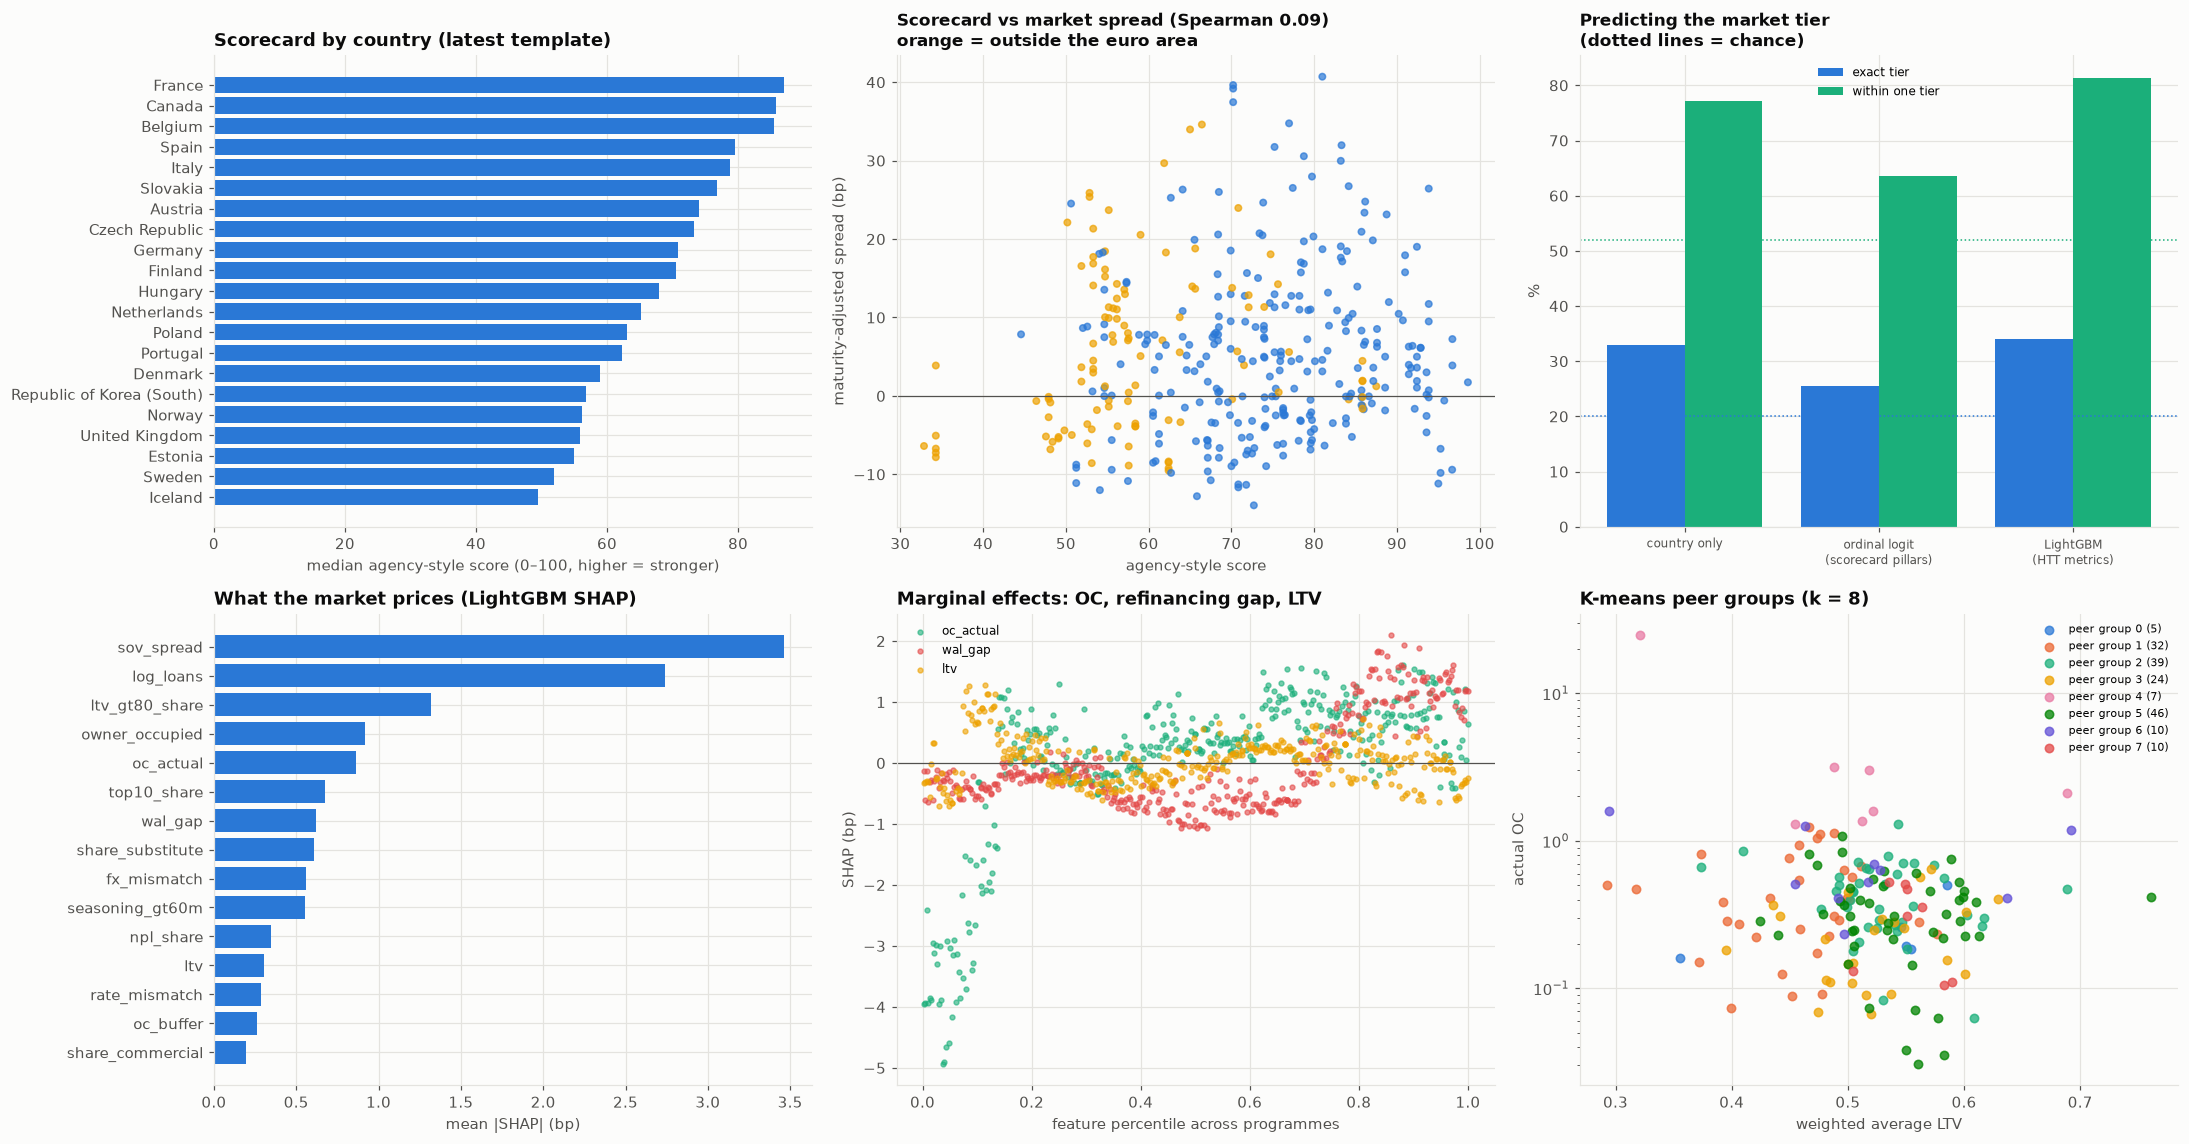

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
lc = latest.groupby("country")["scorecard"].median().sort_values()
lc = lc[latest["country"].value_counts().reindex(lc.index) >= 2]
ax.barh(lc.index, lc.values, color=PALETTE[0])
ax.set_xlabel("median agency-style score (0–100, higher = stronger)")
ax.set_title("Scorecard by country (latest template)")
ax = axes[0, 1]
ax.scatter(
    mk["scorecard"],
    mk["rel_bp"],
    s=18,
    c=mk["non_euro_area"].map({0: PALETTE[0], 1: PALETTE[3]}),
    alpha=0.7,
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("agency-style score")
ax.set_ylabel("maturity-adjusted spread (bp)")
rho_ = stats.spearmanr(mk["scorecard"], mk["rel_bp"], nan_policy="omit")[0]
ax.set_title(
    f"Scorecard vs market spread (Spearman {rho_:.2f})\norange = outside the"
    " euro area",
    fontsize=11,
)
ax = axes[0, 2]
ev_ = evals.drop(
    index=["scorecard alone (higher score = tighter)", "chance (5 tiers)"]
)
xx = np.arange(len(ev_))
ax.bar(
    xx - 0.2, ev_["exact tier %"], 0.4, color=PALETTE[0], label="exact tier"
)
ax.bar(
    xx + 0.2,
    ev_["within one tier %"],
    0.4,
    color=PALETTE[2],
    label="within one tier",
)
ax.axhline(20, color=PALETTE[0], ls=":", lw=1)
ax.axhline(52, color=PALETTE[2], ls=":", lw=1)
ax.set_xticks(xx)
ax.set_xticklabels([s.replace(" (", "\n(") for s in ev_.index], fontsize=8)
ax.set_ylabel("%")
ax.set_title(
    "Predicting the market tier\n(dotted lines = chance)", fontsize=11
)
ax.legend(fontsize=8)
ax = axes[1, 0]
ax.barh(shap_imp.index[::-1], shap_imp.values[::-1], color=PALETTE[0])
ax.set_xlabel("mean |SHAP| (bp)")
ax.set_title("What the market prices (LightGBM SHAP)")
ax = axes[1, 1]
for f_, c in [
    ("oc_actual", PALETTE[2]),
    ("wal_gap", PALETTE[7]),
    ("ltv", PALETTE[3]),
]:
    i = RAW.index(f_)
    xs = mk[f_].rank(pct=True)
    ax.scatter(xs, sv[:, i], s=10, alpha=0.6, color=c, label=f_)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("feature percentile across programmes")
ax.set_ylabel("SHAP (bp)")
ax.legend(fontsize=8)
ax.set_title("Marginal effects: OC, refinancing gap, LTV")
ax = axes[1, 2]
for g_, c in zip(sorted(lt["peer_group"].unique()), PALETTE):
    s_ = lt[lt["peer_group"] == g_]
    ax.scatter(
        s_["ltv"],
        s_["oc_actual"],
        s=30,
        color=c,
        alpha=0.75,
        label=f"peer group {g_} ({len(s_)})",
    )
ax.set_xlabel("weighted average LTV")
ax.set_ylabel("actual OC")
ax.set_yscale("log")
ax.legend(fontsize=7)
ax.set_title(f"K-means peer groups (k = {K_BEST})")
plt.tight_layout()
save_fig(fig, "01_covered_bond_programme_scoring")
plt.show()

## 9. Reading the results and limitations

**The data.**
- 557 half-yearly templates from 173 mortgage programmes in 22 countries, from 2023-H2 to 2026-H2, were parsed from the original HTT workbooks.
- The coverage of the core fields is near-complete: OC, WAL, interest-rate and currency mix, NPLs, concentration.
- The LTV distribution fields are the weakest, about 80% filled, because issuers place them differently.

**The scorecard.**
- The median programme scores 71/100.
- France, Canada, Belgium, Spain and Italy score highest. Their structures carry small asset–liability WAL gaps (soft-bullet bonds with long maturities, or amortising pools) and high OC.
- Iceland, Sweden, Estonia, the UK and Norway score lowest, mostly on the **refinancing pillar**: their pools have contractual lives of 20+ years against bonds of 3–5 years.
- Collateral quality barely discriminates. Almost every pool has indexed LTVs of 45–60% and essentially zero NPLs. That is why agencies rely on the legal framework and the issuer anchor, and why spreads have to come from somewhere else.

**What the market prices.**
- **The scorecard alone does not explain spreads** (Spearman −0.09): a programme the agency-style score calls stronger is, if anything, slightly wider.
- The reason is visible in the ordinal logit:
  - the **sovereign spread** dominates (+0.92 per s.d.);
  - the refinancing pillar works in the expected direction (+0.35: a larger WAL gap means a wider tier);
  - the **OC cushion works backwards** (−0.39): programmes with thin OC trade *tighter*.
- High OC is a signal of a weaker issuer or jurisdiction. Agencies demand more of it before granting the triple-A. The median Italian and Spanish programme holds about 50%, and Czech and Austrian programmes far more, while Danish, Finnish and Dutch programmes run with 7–20% and German ones about 30%.
- **LightGBM on the raw HTT metrics predicts tiers best**:
  - Spearman 0.66 against 0.54 for the country benchmark and 0.45 for the ordinal logit;
  - within-one-tier accuracy 81% against 77% and 64%;
  - exact-tier accuracy is only 34% against 20% by chance. Tier boundaries are a few basis points apart, so exact tiers are noisy.
- SHAP ranks the **sovereign spread** first, then **pool granularity** (number of loans: large, granular pools trade tighter), the share of high-LTV loans, owner occupation and OC.
- The marginal-effects chart shows the OC paradox clearly: the thinnest OC decile is worth −3 to −5 bp.

**Shadow tiers and peer groups.**
- 56 programmes have no euro benchmark bond in the ETF, mostly Danish, Finnish, British and Polish issuers and smaller Spanish, Italian and Portuguese banks. Many fund only in their domestic currency or in sub-benchmark sizes. The model gives them a market-implied tier from their HTT metrics.
- K-means separates eight peer groups, among them:
  - commercial-heavy programmes (Hamburg Commercial Bank, DLR Kredit), with very different implied tiers: one is a former problem bank, the other a Danish agricultural lender priced like its peers;
  - long-WAL Nordic pools;
  - granular low-OC pools;
  - high-OC Southern and Central European pools.

**Limitations.**
- The "market tier" uses the euro benchmark universe of one ETF. Programmes are matched by issuer name within a country, so a bank with several mortgage programmes gets the same spread for each. The matching audit is in the outputs.
- Spreads are relative to the maturity bucket over the AAA government curve. They mix credit, liquidity, the bond's size and the swap basis.
- Templates that are still in the legacy `.xls` format, and fields placed in non-standard rows, are lost. About 20% of selected templates could not be parsed.
- The scorecard thresholds are illustrative, close to published agency bands but not any agency's model. The legal framework, the issuer rating and the resolution regime, the core of real covered-bond ratings, are not in the HTT and are absent here.
- With 117 programmes the results are cross-sectional evidence over three years, not a validated rating model.

In [9]:
h.drop(columns=["file"]).to_csv(
    OUT_DIR / "htt_metrics_and_scorecard.csv", index=False
)
match.to_csv(OUT_DIR / "issuer_matching_audit.csv", index=False)
evals.to_csv(OUT_DIR / "market_tier_model_scores.csv")
shap_imp.to_csv(
    OUT_DIR / "market_pricing_shap.csv", header=["mean_abs_shap_bp"]
)
ord_coef.to_csv(OUT_DIR / "ordinal_logit_coefficients.csv")
lt[[
    "issuer",
    "country",
    "programme",
    "cutoff",
    "scorecard",
    "shadow_rel_bp",
    "shadow_tier",
    "peer_group",
    "has_market_spread",
]].to_csv(OUT_DIR / "latest_scores_and_peer_groups.csv", index=False)
peer.to_csv(OUT_DIR / "peer_groups.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_covered_bond_programme_scoring.png, htt_metrics_and_scorecard.csv, issuer_matching_audit.csv, latest_scores_and_peer_groups.csv, market_pricing_shap.csv, market_tier_model_scores.csv, ordinal_logit_coefficients.csv, peer_groups.csv


## References

### Finance and regulation

- European Parliament & Council of the European Union. (2019). *Directive (EU) 2019/2162 on the issue of covered bonds and covered bond public supervision*. https://eur-lex.europa.eu/eli/dir/2019/2162/oj
- Packer, F., Stever, R., & Upper, C. (2007). The covered bond market. *BIS Quarterly Review*, September, 43–55. https://www.bis.org/publ/qtrpdf/r_qt0709f.htm
- Prokopczuk, M., Siewert, J. B., & Vonhoff, V. (2013). Credit risk in covered bonds. *Journal of Empirical Finance, 21*, 102–120. https://doi.org/10.1016/j.jempfin.2012.12.003
- Svensson, L. E. O. (1994). *Estimating and interpreting forward interest rates: Sweden 1992–1994* (NBER Working Paper No. 4871). National Bureau of Economic Research. https://doi.org/10.3386/w4871

### Machine learning and deep learning

- McCullagh, P. (1980). Regression models for ordinal data. *Journal of the Royal Statistical Society: Series B, 42*(2), 109–127. https://doi.org/10.1111/j.2517-6161.1980.tb01109.x
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Christen, P. (2012). *Data matching: Concepts and techniques for record linkage, entity resolution, and duplicate detection*. Springer. https://doi.org/10.1007/978-3-642-31164-2